# DBCCA — daily precipitation, ACCESS-CM2, Southeast Asia

Statistical downscaling with DBCCA (Werner & Cannon 2016) for one variable (pr), one GCM (ACCESS-CM2) and one observational dataset (MSWEP), with an out-of-sample test: the method is trained on **1981–1998** and evaluated against OBS on **1999–2014**.

**Inputs — the only two files needed**

| | file | content |
|---|---|---|
| OBS | `SEA-mswep-pr-1981-end2014.nc` | MSWEP daily precipitation, 0.25°, 140×140 box over Southeast Asia, 1981–2014 |
| GCM | `pr_combined_histssp245_ACCESS-CM2.nc` | ACCESS-CM2 daily precipitation on its native grid (1.25°×1.875°), historical + SSP2-4.5, covering the OBS box with a margin; only 1981–2014 is read |

Units (kg m⁻² s⁻¹ or mm/day) and calendars are harmonised when the files are read (mm/day, `noleap`). Set the two folders in section 1; nothing else needs editing and nothing is written to disk.

**Method.** DBCCA is BCCA (Maurer et al. 2010) — quantile mapping on the GCM grid followed by constructed analogues (Hidalgo et al. 2008) — plus a second quantile mapping on the fine grid.

| step | what it does | function (section 2) |
|---|---|---|
| coarse grid | OBS 0.25° aggregated onto the GCM's native grid (cos(lat)-weighted mean of the fine cells in each GCM cell) | `coarsen_obs` |
| 1 · DQM on the GCM grid | detrended quantile mapping per calendar month (xclim) | `dqm_coarse` → `bias_correct_gcm` |
| 2 · constructed analogues, GCM grid → 0.25° | for each day: the 30 closest observed days of the same season, ridge-regression weights, the same weights applied to the 0.25° OBS of those days | `ca_fast`, `get_time_mapper` |
| 3 · QDM on the 0.25° grid | quantile delta mapping (Cannon et al. 2015) per 0.25° cell and calendar month (xclim) | `qdm_fine` → `bias_correct_gcm` |

**Settings (pr)**

| parameter | value | meaning |
|---|---|---|
| `CAL`, `VAL` | 1981–1998, 1999–2014 | training period, evaluation period |
| `C['regrid']` | conservative | OBS → GCM grid |
| `C['kd']`, `C['nqd']`, `C['jit']` | `*`, 20, 0.05 mm/day | DQM: multiplicative, 20 quantiles; values < 0.05 mm/day replaced by small noise to avoid division by 0 |
| `NA`, `WIN`, `ALPHA`, `C['tr']` | 30, ±45 days, 1.0, sqrt | CA: analogues, seasonal window, ridge penalty, transform of pr |
| `C['kq']`, `C['nqq']` | `+`, 50 | QDM: additive, 50 quantiles, no noise |
| `C['lim']` | (0, None) | output clipped at 0 |
| `SEED` | 0 | random seed of the noise; the run is reproducible |
| `BATCH`, `CHUNK_LL` | 48, 35 | CA days per batch, QDM chunk size (speed only) |

The final QDM is trained on the CA output of the calibration period, so DQM and CA are applied to the whole 1981–2014 GCM series and only 1999–2014 is evaluated; OBS 1999–2014 never enters the method.

**Requirements**: numpy, pandas, xarray, dask, xclim (or xsdba), matplotlib, cartopy, shapely. Runtime a few minutes. Cells build on each other: run them top to bottom once, after that any cell can be re-run on its own.

## 1 · Setup
Inputs, settings and helpers.

In [1]:
import os, time, gc, warnings, numpy as np, pandas as pd, xarray as xr, dask, matplotlib.pyplot as plt
import cartopy.crs as ccrs, cartopy.feature as cfeature, cartopy.io.shapereader as shpreader, shapely
warnings.filterwarnings('ignore'); plt.rcParams['text.usetex'] = False; dask.config.set(scheduler='threads', num_workers=4)
try: from xclim import sdba
except Exception: import xsdba as sdba                                                         # newer xclim: sdba lives in xsdba
# ======================================== CONFIG (your data dirs) ========================================
OBS_DIR, IN_ROOT = r"D:/G_data/obs-SEA", r"D:/G_data/CMIP6-histssp-input"                      # same inputs as the ISIMIP3BASD notebook
V, MOD, OBS_NAME, SCN = 'pr', 'ACCESS-CM2', 'MSWEP', 'ssp245'
OBS_FILE = rf"{OBS_DIR}/SEA-mswep-pr-1981-end2014.nc"
GCM_FILE = rf"{IN_ROOT}/histssp{SCN[3:]}/{V}_combined_histssp{SCN[3:]}_{MOD}.nc"               # only its 1981-2014 (historical) part is used
CAL, VAL = ('1981', '1998'), ('1999', '2014')                                                  # calibration -> validation (out of sample)
NA, WIN, ALPHA, BATCH, CHUNK_LL, SEED = 30, 45, 1.0, 48, 35, 0                                 # analogues, +-days window, ridge alpha | CA batch, QDM dask chunk, seed
# pr settings: DQM (GCM grid) multiplicative + jitter, CA on sqrt(pr), QDM (0.25°) additive without jitter
C = dict(units='mm/day', kd='*', nqd=20, kq='+', nqq=50, tr='sqrt', jit=.05, lim=(0., None), regrid='conservative', thr=1.)
TAGCFG = (f'cal={CAL[0]}-{CAL[1]} val={VAL[0]}-{VAL[1]} dqm={C["kd"]},nq={C["nqd"]},jit={C["jit"]} ca=na{NA},win+-{WIN},alpha{ALPHA},{C["tr"]} '
          f'qdm={C["kq"]},nq={C["nqq"]} regrid={C["regrid"]} seed={SEED}')
for _p in (OBS_FILE, GCM_FILE): assert os.path.exists(_p), f'not found: {_p}'
print(f'quantile mapping from {sdba.__name__} | xarray {xr.__version__} | {TAGCFG}', flush=True)
# ======================================== HELPERS ========================================
def std(ds):
    ren = {a:b for a,b in [('latitude','lat'),('longitude','lon'),('Latitude','lat'),('Longitude','lon')] if a in ds.dims or a in ds.coords}
    ds = ds.rename(ren) if ren else ds
    if ds.lat.size > 1 and float(ds.lat[0]) > float(ds.lat[-1]): ds = ds.sortby('lat')
    if float(ds.lon.min()) < 0: ds = ds.assign_coords(lon=(ds.lon % 360)).sortby('lon')
    return ds
NL = lambda d: d if d.time.dt.calendar=='noleap' else d.convert_calendar('noleap', align_on='year' if d.time.dt.calendar=='360_day' else 'date')
Tz = lambda d: d.transpose('time','lat','lon')
def fix_units(da, v, name):
    u = str(da.attrs.get('units','')).lower().replace(' ',''); s = da.isel(time=slice(0, 366)); msg = None
    if v == 'pr' and (u in ('kgm-2s-1','kg/m2/s','kgm**-2s**-1') or 0 < float(s.max()) < 0.01): da, msg = da*86400., 'x86400'
    if msg: print(f'    !! {name}: units="{u}" -> {msg}', flush=True)
    da.attrs = {'units': C['units']}; return da
_RNG = np.random.default_rng(SEED)                                                             # reset in section 4 -> the same noise on every re-run
def jitter(a, thr):
    """Values below thr -> uniform noise in (1e-10, thr), so the multiplicative DQM never divides by 0."""
    m = a < thr; return np.where(m, _RNG.uniform(1e-10, thr, a.shape), a) if m.any() else a
def land_mask(lat, lon):
    """Natural Earth 10m land polygons (cartopy) evaluated at the grid points; None if the polygons cannot be loaded."""
    try:
        lo = (np.asarray(lon) + 180) % 360 - 180; box = shapely.box(lo.min()-1, lat.min()-1, lo.max()+1, lat.max()+1)
        g = shapely.union_all([shapely.intersection(x, box) for x in shpreader.Reader(shpreader.natural_earth('10m', 'physical', 'land')).geometries() if x.intersects(box)])
        LO, LA = np.meshgrid(lo, lat); return shapely.contains_xy(g, LO, LA)
    except Exception as e: print(f'!! Natural Earth land unavailable ({type(e).__name__}: {e}) -> mask = finite OBS only', flush=True); return None

C:\Users\HOASEN\AppData\Roaming\Python\Python39\site-packages\pandas\core\arrays\masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


quantile mapping from xclim.sdba | xarray 2024.7.0 | cal=1981-1998 val=1999-2014 dqm=*,nq=20,jit=0.05 ca=na30,win+-45,alpha1.0,sqrt qdm=+,nq=50 regrid=conservative seed=0


## 2 · DBCCA
`coarsen_obs`, `bias_correct_gcm` and `get_time_mapper` set up the coarse grid, the quantile mappings and the seasonal window. `ca_fast` builds the constructed analogues for a batch of days at once:

1. **analogues** — RMSE over the coarse cells against every observed day within ±`WIN` days of the day of year; keep the `NA` smallest;
2. **weights** — ridge regression without intercept, `w = (X Xᵀ + αI)⁻¹ X g`;
3. **downscaled field** — the same weights applied to the 0.25° OBS of those days; with `sqrt`, the analogues and weights are computed on √pr and the result is squared back.

`dqm_coarse` and `qdm_fine` are the two quantile mappings with the noise, clipping and printing around them.

In [2]:
# ======================================== coarse grid, quantile mapping, seasonal window ========================================
class Regridder:
    """Regridding of the fine OBS onto the GCM grid. 'conservative' = cos(lat)-weighted mean of the fine cells whose centres fall in each
       coarse cell (keeps the areal pr total); 'bilinear' = linear interpolation. Cell edges = midpoints between the coarse centres."""
    def __init__(self, ds_out, method='bilinear'): self.lat, self.lon, self.method = np.asarray(ds_out.lat.values, float), np.asarray(ds_out.lon.values, float), method
    @staticmethod
    def edges(c): c = np.asarray(c, float); m = (c[:-1]+c[1:])/2; return np.concatenate([[2*c[0]-m[0]], m, [2*c[-1]-m[-1]]])
    def __call__(self, da):
        if self.method == 'bilinear': return da.interp(lat=self.lat, lon=self.lon, method='linear')
        w = np.cos(np.radians(da.lat)); eb, eo = self.edges(self.lat), self.edges(self.lon)
        num = (da*w).groupby_bins('lat', eb, labels=self.lat).sum('lat'); den = w.groupby_bins('lat', eb, labels=self.lat).sum('lat')
        return (num/den).groupby_bins('lon', eo, labels=self.lon).mean('lon').rename({'lat_bins':'lat','lon_bins':'lon'}).reindex(lat=self.lat, lon=self.lon)
def coarsen_obs(obs, ds_coarse, method='bilinear', regridder=None, return_regridder=False):
    """Regrid the fine OBS onto the lat/lon grid of ds_coarse (the GCM)."""
    regridder = regridder if regridder is not None else Regridder(ds_coarse, method); o = regridder(obs)
    return (o, regridder) if return_regridder else o
def bias_correct_gcm(gcm_hist, gcm_future, obs_data, method='DQM', grouper='time.month', kind='+', nquantiles=20):
    """Train an sdba quantile mapping on (obs_data, gcm_hist), adjust gcm_hist and gcm_future.
       All three need a 'units' attribute; obs_data and gcm_hist must cover the same period."""
    BA = {'DQM': sdba.DetrendedQuantileMapping, 'QDM': sdba.QuantileDeltaMapping, 'EQM': sdba.EmpiricalQuantileMapping}[method]
    T = BA.train(obs_data, gcm_hist, group=grouper, kind=kind, nquantiles=nquantiles); return T.adjust(gcm_hist), T.adjust(gcm_future)
def get_time_mapper(window_size, window_unit='days'):
    """Day of year (1..365) -> the days of year within +-window_size days, wrapping over the year end."""
    out = {}
    for day in range(1, 366):
        lo, hi = (day - window_size - 365) % 365, (day + window_size + 365) % 365
        out[day] = np.append(np.arange(lo, 366), np.arange(1, hi + 1)) if lo > hi else np.arange(lo, hi + 1)
    return out
# ======================================== constructed analogues ========================================
def ca_fast(gcm_bc, obs_c, obs_f, c, n_analogues=NA, window_size=WIN, alpha=ALPHA, batch=BATCH):
    """For every day of gcm_bc (GCM grid): the n_analogues days of the coarse OBS library obs_c within +-window_size days of the day of year
       closest in Euclidean distance over the coarse cells with OBS, ridge weights w = (X X' + alpha I)^-1 X g, and the same w applied to the
       fine OBS obs_f of those days. c['jit'] / c['tr'] switch jitter and the sqrt transform on (None = off)."""
    t0 = time.time(); g3, o3, f3 = Tz(gcm_bc), Tz(obs_c), Tz(obs_f); tr, jit = c['tr'], c['jit']
    nt, nlat, nlon = g3.time.size, f3.lat.size, f3.lon.size
    Cm = np.isfinite(o3.isel(time=0).values).ravel(); Fm = np.isfinite(f3.isel(time=0).values).ravel()
    OC = np.nan_to_num(o3.values.reshape(o3.time.size, -1)[:, Cm]).astype('f8')
    OF = np.nan_to_num(f3.values.reshape(f3.time.size, -1)).astype('f4')
    GC = np.nan_to_num(g3.values.reshape(nt, -1)[:, Cm]).astype('f8')
    if jit: OC, GC = jitter(OC, jit), jitter(GC, jit)
    if tr == 'sqrt': OC, OF, GC = np.sqrt(np.maximum(OC, 0)), np.sqrt(np.maximum(OF, 0)), np.sqrt(np.maximum(GC, 0))
    tm = get_time_mapper(window_size, 'days'); odoy, gdoy = o3.time.dt.dayofyear.values, g3.time.dt.dayofyear.values
    ocn = (OC**2).sum(1); OUT = np.empty((nt, OF.shape[1]), 'f4'); eye = np.eye(n_analogues)*alpha; doys = np.unique(gdoy); done = 0
    for j, d in enumerate(doys):
        ci = np.where(np.isin(odoy, tm[int(d)]))[0]; Cl, Cn, F = OC[ci], ocn[ci], OF[ci]; gi = np.where(gdoy == d)[0]   # library of this day of year
        for b0 in range(0, len(gi), batch):
            bi = gi[b0:b0+batch]; Gb = GC[bi]
            d2 = (Gb**2).sum(1)[:, None] + Cn[None, :] - 2.0*(Gb @ Cl.T)                       # 1) squared distance to every library day
            k = np.argpartition(d2, n_analogues-1, axis=1)[:, :n_analogues]
            k = np.take_along_axis(k, np.argsort(np.take_along_axis(d2, k, 1), axis=1), 1); X = Cl[k]
            w = np.linalg.solve(X @ X.transpose(0, 2, 1) + eye, np.einsum('bnp,bp->bn', X, Gb))  # 2) ridge weights, one set per GCM day
            OUT[bi] = np.einsum('bn,bnp->bp', w.astype('f4'), F[k]); del Gb, d2, k, X, w           # 3) weighted fine OBS
        done += len(gi)
        if (j+1) % 73 == 0 or j == len(doys)-1:
            el = time.time()-t0; print(f'      [CA] {done}/{nt} days | {el/60:.1f} min | eta {el/(j+1)*(len(doys)-j-1)/60:.1f} min', flush=True)
    if tr == 'sqrt': OUT = np.maximum(OUT, 0)**2
    OUT[:, ~Fm] = np.nan; del OC, OF, GC, F; gc.collect()
    d = xr.DataArray(OUT.reshape(nt, nlat, nlon), dims=('time','lat','lon'), coords={'time': g3.time, 'lat': f3.lat, 'lon': f3.lon}, name=V, attrs={'units': c['units']})
    print(f'    [CA] {(time.time()-t0)/60:.1f} min | coarse cells {int(Cm.sum())} | library {o3.time.size} days | mean {float(d.mean()):.2f} {c["units"]}', flush=True); return d
# ======================================== the two bias corrections of DBCCA ========================================
def dqm_coarse(oc, g, c):
    """DQM on the GCM grid: trained on (coarse OBS, GCM) in CAL, applied to the whole GCM series g."""
    t = time.time(); U = c['units']
    J = lambda x: (xr.apply_ufunc(jitter, x, c['jit']) if c['jit'] else x).assign_attrs(units=U)
    oj, gj = J(oc), J(g)
    _, d = bias_correct_gcm(gj.sel(time=slice(*CAL)), gj, oj, method='DQM', kind=c['kd'], nquantiles=c['nqd'], grouper='time.month')
    d = Tz(d.compute().astype('float32')).clip(*c['lim']).rename(V); d.attrs = {'units': U}
    print(f'    [DQM] {time.time()-t:.0f}s | {CAL[0]}-{CAL[1]} mean: GCM {float(g.sel(time=slice(*CAL)).mean()):.2f} -> DQM {float(d.sel(time=slice(*CAL)).mean()):.2f} '
          f'(coarse OBS {float(oc.mean()):.2f}) {U}', flush=True); return d
def qdm_fine(bcca, of, c):
    """QDM per 0.25° cell and calendar month: trained on (BCCA, fine OBS) in CAL, applied to the whole BCCA series."""
    t = time.time(); U = c['units']; ck = {'time': -1, 'lat': CHUNK_LL, 'lon': CHUNK_LL}
    bT = bcca.assign_coords(lat=of.lat, lon=of.lon).chunk(ck); bT.attrs = {'units': U}
    oT = of.chunk(ck); oT.attrs = {'units': U}
    _, d = bias_correct_gcm(bT.sel(time=slice(*CAL)), bT, oT, method='QDM', kind=c['kq'], nquantiles=c['nqq'], grouper='time.month')
    d = Tz(d.compute().astype('float32').rename(V)); lo, hi = c['lim']; dv = d.values
    bad = 100*float(np.nanmean((dv < (-np.inf if lo is None else lo)) | (dv > (np.inf if hi is None else hi)))); del dv
    d = d.clip(lo, hi); d.attrs = {'units': U}; del bT, oT; gc.collect()
    print(f'    [QDM] {(time.time()-t)/60:.1f} min | outside {c["lim"]}: {bad:.3f}% -> clipped | DBCCA mean {float(d.mean()):.2f} {U}', flush=True); return d
print('DBCCA functions ready', flush=True)

DBCCA functions ready


## 3 · Load the data and build the coarse grid
Both files are read for 1981–2014. DBCCA works on the **GCM's own grid**: `coarsen_obs` aggregates the 0.25° OBS of the calibration period onto it, and GCM cells without OBS underneath are masked.

In [3]:
def load(f, name):
    ds = std(xr.open_dataset(f)); vn = V if V in ds.data_vars else list(ds.data_vars)[0]
    d = Tz(fix_units(NL(ds[vn].sel(time=slice(CAL[0], VAL[1]))).astype('float32').load(), V, name)).rename(V); ds.close(); return d
OBS, G = load(OBS_FILE, 'obs'), load(GCM_FILE, MOD)
lat_f, lon_f = OBS.lat.values, OBS.lon.values; dg, dgx = float(np.median(np.diff(G.lat.values))), float(np.median(np.diff(G.lon.values)))
OBS_CAL, OBS_VAL = OBS.sel(time=slice(*CAL)), OBS.sel(time=slice(*VAL)); OBS_CAL.attrs = {'units': C['units']}
t = time.time(); OC_C = Tz(coarsen_obs(OBS_CAL, G, C['regrid']).astype('float32')).rename(V); OC_C.attrs = {'units': C['units']}   # OBS 0.25° -> GCM grid, calibration only
land_c = ~np.isnan(OC_C.isel(time=0)); G_C = G.where(land_c); G_C.attrs = {'units': C['units']}                                   # GCM cells that have OBS underneath
assert int(land_c.sum()) > NA, f'only {int(land_c.sum())} coarse cells with OBS: check that the GCM crop covers the OBS box'
print(f'OBS {dict(OBS.sizes)} | {MOD} native {G.lat.size}x{G.lon.size} ({dg:.2f}°x{dgx:.2f}°) = DBCCA coarse grid | '
      f'OBS -> coarse ({C["regrid"]}) {time.time()-t:.0f}s | coarse cells with OBS {int(land_c.sum())}/{land_c.size}\n'
      f'calibration {CAL[0]}-{CAL[1]}: {OBS_CAL.time.size} days | validation {VAL[0]}-{VAL[1]}: {OBS_VAL.time.size} days', flush=True)

OBS {'time': 12410, 'lat': 140, 'lon': 140} | ACCESS-CM2 native 41x28 (1.25°x1.88°) = DBCCA coarse grid | OBS -> coarse (conservative) 3s | coarse cells with OBS 580/1148
calibration 1981-1998: 6570 days | validation 1999-2014: 5840 days


## 4 · DQM (GCM grid) → constructed analogues (→ 0.25°) → QDM (0.25°)
* **DQM**: trained on 1981–1998, applied to the GCM 1981–2014 on its own grid.
* **CA**: the analogue library is OBS 1981–1998 only. The result is BCCA; each day is a weighted mean of 30 observed days, so BCCA is too smooth: weaker heavy-rain days and too many drizzle days.
* **QDM**: per 0.25° cell and month, trained on BCCA vs OBS in 1981–1998 and applied to BCCA 1981–2014; this second quantile mapping restores the local distribution of daily pr.

If this configuration was already run in this kernel, the cell does nothing; set `RERUN = True` to force the computation.

In [4]:
RERUN = False
if not RERUN and globals().get('_DONE') == (GCM_FILE, TAGCFG): print('DBCCA for this configuration is in memory -> nothing to run', flush=True)
else:
    t0 = time.time(); _RNG = np.random.default_rng(SEED)                                       # same jitter noise on every re-run
    DQM_C = dqm_coarse(OC_C, G_C, C)                                                           # 1) DQM on the GCM grid, 1981-2014
    BCCA = ca_fast(DQM_C, OC_C, OBS_CAL, C)                                                    # 2) CA with the 1981-1998 OBS library -> 0.25°
    DBCCA = qdm_fine(BCCA, OBS_CAL, C)                                                         # 3) QDM per 0.25° cell, trained 1981-1998
    _DONE = (GCM_FILE, TAGCFG); gc.collect(); print(f'DQM + CA + QDM done in {(time.time()-t0)/60:.1f} min | DBCCA {dict(DBCCA.sizes)}', flush=True)

    [DQM] 19s | 1981-1998 mean: GCM 6.99 -> DQM 5.76 (coarse OBS 5.71) mm/day
      [CA] 2482/12410 days | 0.1 min | eta 0.4 min
      [CA] 4964/12410 days | 0.3 min | eta 0.4 min
      [CA] 7446/12410 days | 0.5 min | eta 0.3 min
      [CA] 9928/12410 days | 0.6 min | eta 0.1 min
      [CA] 12410/12410 days | 0.8 min | eta 0.0 min
    [CA] 0.8 min | coarse cells 580 | library 6570 days | mean 4.82 mm/day
    [QDM] 2.6 min | outside (0.0, None): 4.334% -> clipped | DBCCA mean 5.68 mm/day
DQM + CA + QDM done in 3.8 min | DBCCA {'time': 12410, 'lat': 140, 'lon': 140}


### 4b · (optional) check of `ca_fast`
`ca_original` computes the constructed analogue of one day in the plain way (RMSE ranking with xarray, ridge weights as a least-squares problem, weighted sum of the 0.25° OBS). Both are run on five random days without noise and transform; the difference should be at float32 round-off. Takes a few seconds.

In [5]:
def ca_original(i, gcm_bc, obs_c, obs_f, n_analogues=NA, window_size=WIN, alpha=ALPHA):
    g = gcm_bc.isel(time=i); cand = obs_c.sel(time=obs_c.time.dt.dayofyear.isin(get_time_mapper(window_size)[int(g.time.dt.dayofyear)]))
    rm = np.sqrt(((g - cand)**2).mean(['lat', 'lon'], skipna=True)); at = rm.sortby(rm).time.values[:n_analogues]          # 1) RMSE ranking
    X = cand.sel(time=at).stack(s=('lat', 'lon')).fillna(0).values; y = g.stack(s=('lat', 'lon')).fillna(0).values            # 2) stacked fields
    w = np.linalg.lstsq(np.vstack([X.T, np.sqrt(alpha)*np.eye(n_analogues)]), np.r_[y, np.zeros(n_analogues)], rcond=None)[0]  # 2) ridge weights
    return (obs_f.sel(time=at) * xr.DataArray(w, dims='time', coords={'time': at})).sum('time').where(obs_f.isel(time=0).notnull())   # 3) weighted fine OBS
idx = np.sort(np.random.default_rng(SEED + 1).choice(DQM_C.time.size, 5, replace=False))
FAST = ca_fast(DQM_C.isel(time=idx), OC_C, OBS_CAL, dict(C, tr=None, jit=None))
for n, i in enumerate(idx):
    R = ca_original(int(i), DQM_C, OC_C, OBS_CAL); dd = np.abs(Tz(FAST).values[n] - R.values)
    print(f'  {str(DQM_C.time.values[i])[:10]} | field mean {float(R.mean()):6.2f} mm/day | max |ca_fast - original| {np.nanmax(dd):.1e} mm/day', flush=True)
del FAST, R, dd; gc.collect()

      [CA] 5/5 days | 0.1 min | eta 0.0 min
    [CA] 0.1 min | coarse cells 580 | library 6570 days | mean 6.66 mm/day
  1982-03-09 | field mean   3.36 mm/day | max |ca_fast - original| 1.1e-05 mm/day
  1997-01-31 | field mean   7.50 mm/day | max |ca_fast - original| 3.3e-05 mm/day
  1998-05-26 | field mean   6.65 mm/day | max |ca_fast - original| 1.1e-05 mm/day
  2006-09-03 | field mean   9.25 mm/day | max |ca_fast - original| 7.0e-06 mm/day
  2013-04-25 | field mean   6.51 mm/day | max |ca_fast - original| 2.2e-05 mm/day


0

## 5 · Evaluation against OBS, 1999–2014 (out of sample, land only)
All fields are compared on the 0.25° grid over land points (Natural Earth 10 m land polygons via cartopy). The raw GCM and the DQM output are bilinearly interpolated to 0.25° only for this comparison (DQM points next to masked GCM cells take the nearest cell). `BCCA` is the field after CA and before the final QDM, so the rows show what each step adds.

| column | meaning |
|---|---|
| `mean`, `bias`, `rel_pct` | land-mean daily pr, its difference from OBS, and that difference in % |
| `rmse`, `r_spatial` | RMSE and spatial correlation of the 16-year mean map |
| `sd_ratio` | temporal standard deviation of daily pr relative to OBS |
| `p99`, `dp99` | 99th percentile of daily pr per grid point (land mean) and its difference from OBS |
| `wet_pct`, `dwet` | share of days with pr ≥ 1 mm and its difference from OBS (percentage points) |

In [6]:
LM0 = land_mask(lat_f, lon_f); NE = LM0 is not None
LM = (LM0 if NE else np.ones((lat_f.size, lon_f.size), bool)) & np.isfinite(OBS_VAL.isel(time=0).values)
up = lambda d: d.interp(lat=lat_f, lon=lon_f, method='linear', kwargs={'fill_value': None}).combine_first(
               d.interp(lat=lat_f, lon=lon_f, method='nearest', kwargs={'fill_value': None}))
GV = G.sel(time=slice(*VAL)); GK, DK = f'{MOD} raw', f'DQM {dg:.2f}°'
SER = {'OBS': OBS_VAL, GK: GV.interp(lat=lat_f, lon=lon_f, method='linear'), DK: up(DQM_C.sel(time=slice(*VAL))),
       'BCCA': BCCA.sel(time=slice(*VAL)), 'DBCCA': DBCCA.sel(time=slice(*VAL))}
QP = np.r_[np.arange(80., 99., 1.), np.arange(99., 99.95, .1)]
def ev(da, mask=True):
    a = Tz(da).values.astype('f8')
    if mask: a[:, ~LM] = np.nan
    f = np.isfinite(a)
    with np.errstate(all='ignore'): r = dict(mean=np.nanmean(a, 0), p99=np.nanpercentile(a, 99, 0), wet=100.*((a >= C['thr']) & f).sum(0)/f.sum(0))
    if mask:
        x = a[:, LM]; r.update(sd=float(np.nanmean(np.nanstd(a, 0)[LM])), pq=np.nanpercentile(x, QP), mon=pd.Series(np.nanmean(x, 1)).groupby(da.time.dt.month.values).mean().values)
    return r
def met(S, O):
    b = (S['mean'] - O['mean'])[LM]; ok = np.isfinite(b)
    return dict(mean=np.nanmean(S['mean'][LM]), bias=np.nanmean(b), rel_pct=100*np.nanmean(b)/np.nanmean(O['mean'][LM]), rmse=np.sqrt(np.nanmean(b**2)),
                r_spatial=np.corrcoef(S['mean'][LM][ok], O['mean'][LM][ok])[0, 1], sd_ratio=S['sd']/O['sd'], p99=np.nanmean(S['p99'][LM]),
                dp99=np.nanmean((S['p99'] - O['p99'])[LM]), wet_pct=np.nanmean(S['wet'][LM]), dwet=np.nanmean((S['wet'] - O['wet'])[LM]))
E = {k: ev(d) for k, d in SER.items()}; EN = ev(GV, mask=False)                               # EN: raw GCM on its native grid, for the maps
TAB = pd.DataFrame({k: met(S, E['OBS']) for k, S in E.items()}).T
print(f'validation {VAL[0]}-{VAL[1]} | {int(LM.sum())} land points at 0.25° | land mask: {"Natural Earth 10m (cartopy)" if NE else "finite OBS only"}')
pd.set_option('display.width', 200); print(TAB.round(3).to_string())

validation 1999-2014 | 5790 land points at 0.25° | land mask: Natural Earth 10m (cartopy)
                 mean   bias  rel_pct   rmse  r_spatial  sd_ratio     p99    dp99  wet_pct   dwet
OBS             6.061  0.000    0.000  0.000      1.000     1.000  42.323   0.000   62.574  0.000
ACCESS-CM2 raw  6.346  0.285    4.699  1.538      0.758     1.029  44.314   1.991   61.641 -0.933
DQM 1.25°       5.971 -0.090   -1.491  1.032      0.888     0.861  35.562  -6.761   68.685  6.112
BCCA            5.006 -1.055  -17.410  1.257      0.948     0.589  24.050 -18.273   69.673  7.099
DBCCA           5.781 -0.280   -4.626  0.610      0.969     0.955  43.032   0.709   60.599 -1.974


## 6 · Maps: GCM → OBS → downscaled
Left to right: raw ACCESS-CM2 on its native grid, OBS (MSWEP, 0.25°), DBCCA output (0.25°), and DBCCA − OBS. Rows: mean daily pr, 99th percentile, and wet-day frequency, 1999–2014. The first three columns of a row share one colour scale; numbers in the titles are land means.

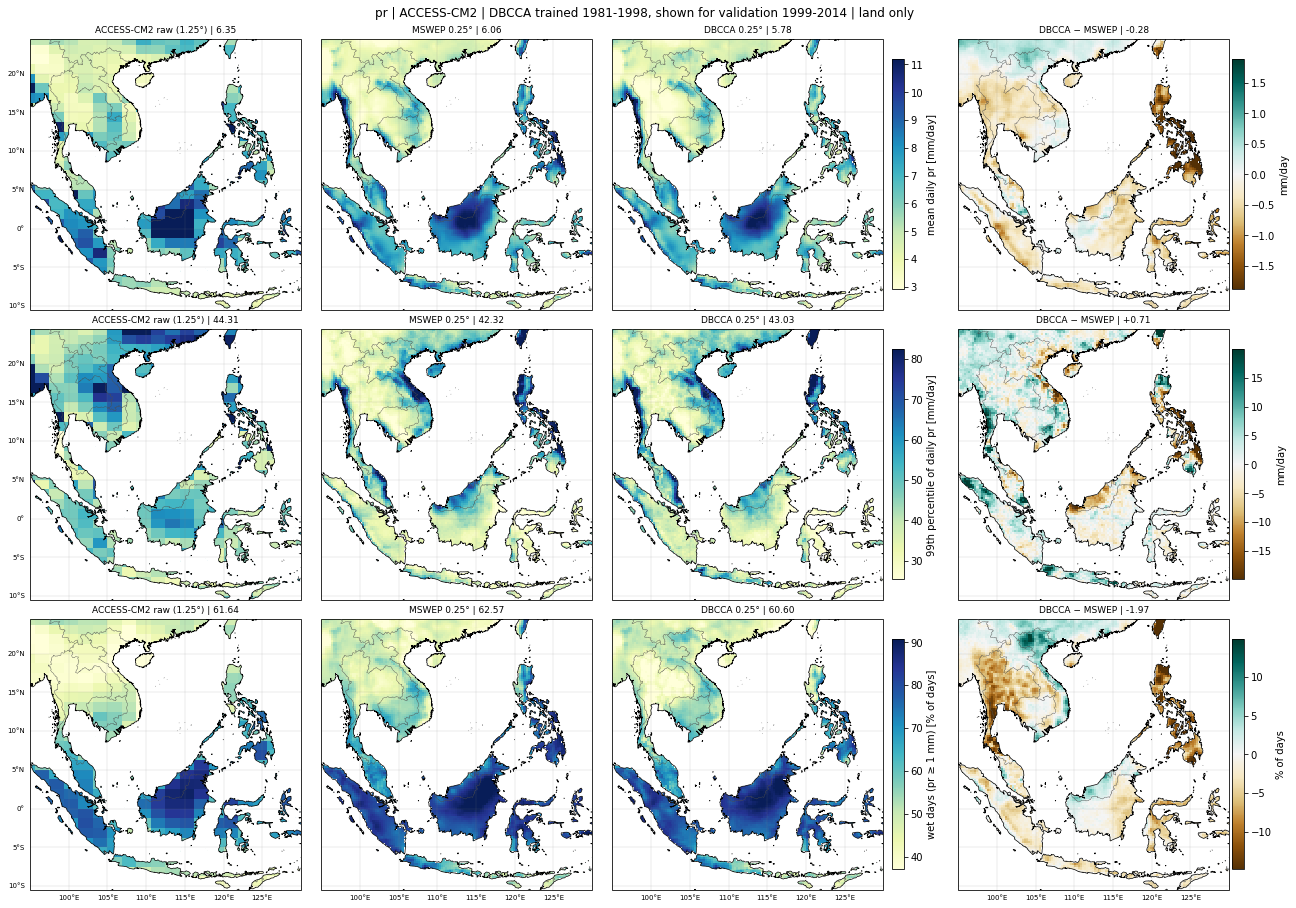

In [7]:
PC = ccrs.PlateCarree(); h = .5*float(np.median(np.diff(lat_f))); EXT = [lon_f[0]-h, lon_f[-1]+h, lat_f[0]-h, lat_f[-1]+h]
def deco(a, r, c, nr=3):
    a.set_extent(EXT, crs=PC)
    if NE:
        a.add_feature(cfeature.NaturalEarthFeature('physical', 'ocean', '10m'), facecolor='white', edgecolor='none', zorder=2)
        a.coastlines('10m', lw=.7, zorder=3); a.add_feature(cfeature.BORDERS.with_scale('10m'), lw=.4, edgecolor='.3', zorder=3)
    gl = a.gridlines(draw_labels=True, lw=.3, color='.5', alpha=.5, zorder=4); gl.top_labels = gl.right_labels = False
    gl.left_labels, gl.bottom_labels = c == 0, r == nr - 1; gl.xlabel_style = gl.ylabel_style = dict(size=7)
ROWS = [('mean', 'mean daily pr', 'mm/day'), ('p99', '99th percentile of daily pr', 'mm/day'), ('wet', f'wet days (pr ≥ {C["thr"]:g} mm)', '% of days')]
fig, ax = plt.subplots(3, 4, figsize=(18, 12.5), subplot_kw=dict(projection=PC), layout='constrained')
for r, (k, nm, u) in enumerate(ROWS):
    lim = np.nanpercentile(np.r_[E['OBS'][k][LM], E['DBCCA'][k][LM], E[GK][k][LM]], [2, 98])
    for c, (x, y, z, t) in enumerate([(GV.lon.values, GV.lat.values, EN[k], f'{MOD} raw ({dg:.2f}°) | {np.nanmean(E[GK][k][LM]):.2f}'),
                                      (lon_f, lat_f, np.where(LM, E['OBS'][k], np.nan), f'{OBS_NAME} 0.25° | {np.nanmean(E["OBS"][k][LM]):.2f}'),
                                      (lon_f, lat_f, np.where(LM, E['DBCCA'][k], np.nan), f'DBCCA 0.25° | {np.nanmean(E["DBCCA"][k][LM]):.2f}')]):
        im = ax[r, c].pcolormesh(x, y, z, cmap='YlGnBu', vmin=lim[0], vmax=lim[1], shading='auto', transform=PC); ax[r, c].set_title(t, fontsize=9); deco(ax[r, c], r, c)
    fig.colorbar(im, ax=ax[r, :3], shrink=.85, pad=.01, label=f'{nm} [{u}]')
    b = np.where(LM, E['DBCCA'][k] - E['OBS'][k], np.nan); vb = max(float(np.nanpercentile(np.abs(b[LM]), 98)), 1e-6)
    im = ax[r, 3].pcolormesh(lon_f, lat_f, b, cmap='BrBG', vmin=-vb, vmax=vb, shading='auto', transform=PC)
    ax[r, 3].set_title(f'DBCCA − {OBS_NAME} | {np.nanmean(b[LM]):+.2f}', fontsize=9); deco(ax[r, 3], r, 3); fig.colorbar(im, ax=ax[r, 3], shrink=.85, pad=.01, label=u)
fig.suptitle(f'{V} | {MOD} | DBCCA trained {CAL[0]}-{CAL[1]}, shown for validation {VAL[0]}-{VAL[1]} | land only', fontsize=12)
plt.show(); plt.close(fig)

## 7 · Distribution, annual cycle, and grid-point means
(a) Upper percentiles of daily pr pooled over land points (log scale): BCCA against DBCCA shows how much of the tail the final QDM restores. (b) Monthly climatology of the land mean. (c) 16-year mean per 0.25° land point against OBS; the 1:1 line is perfect, and the spread of the raw GCM and of the DQM output shows the spatial detail that only CA adds.

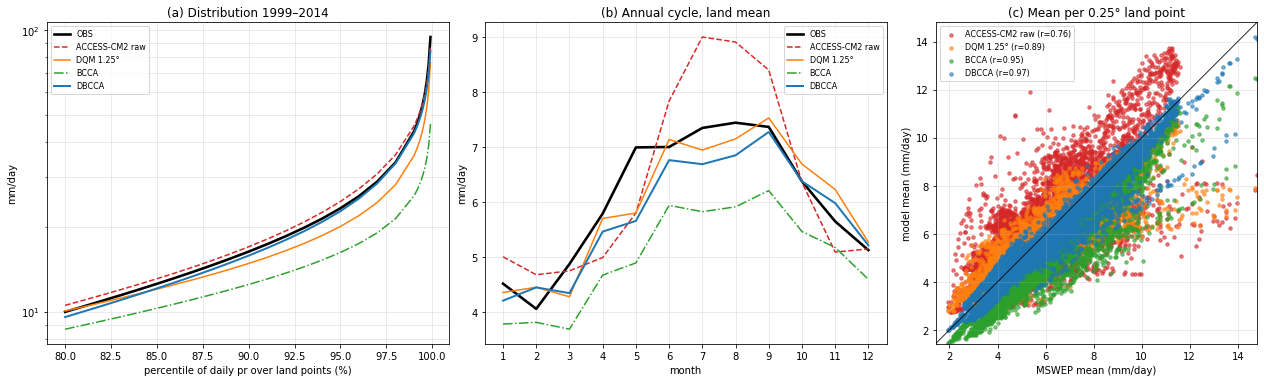

In [8]:
STY = {'OBS': dict(color='k', lw=2.6), GK: dict(color='tab:red', lw=1.5, ls='--'), DK: dict(color='tab:orange', lw=1.5),
       'BCCA': dict(color='tab:green', lw=1.5, ls='-.'), 'DBCCA': dict(color='tab:blue', lw=2)}
fig, ax = plt.subplots(1, 3, figsize=(18, 5.2), layout='constrained')
for k, S in E.items(): ax[0].plot(QP, S['pq'], label=k, **STY[k]); ax[1].plot(range(1, 13), S['mon'], label=k, **STY[k])
o = E['OBS']['mean'][LM]; lo_ = min(np.nanmin(E[k]['mean'][LM]) for k in E); hi_ = max(np.nanmax(E[k]['mean'][LM]) for k in E)
for k in (GK, DK, 'BCCA', 'DBCCA'): ax[2].scatter(o, E[k]['mean'][LM], s=12, alpha=.6, color=STY[k]['color'], label=f'{k} (r={TAB.loc[k, "r_spatial"]:.2f})')
ax[2].plot([lo_, hi_], [lo_, hi_], 'k-', lw=.8)
ax[0].set(yscale='log', xlabel='percentile of daily pr over land points (%)', ylabel='mm/day', title=f'(a) Distribution {VAL[0]}–{VAL[1]}')
ax[1].set(xticks=range(1, 13), xlabel='month', ylabel='mm/day', title='(b) Annual cycle, land mean')
ax[2].set(xlim=(lo_, hi_), ylim=(lo_, hi_), aspect='equal', xlabel=f'{OBS_NAME} mean (mm/day)', ylabel='model mean (mm/day)', title='(c) Mean per 0.25° land point')
for a in ax: a.grid(alpha=.3, which='both'); a.legend(fontsize=8)
plt.show(); plt.close(fig)

## References
* Werner, A. T., & Cannon, A. J. (2016). Hydrologic extremes – an intercomparison of multiple gridded statistical downscaling methods. *Hydrology and Earth System Sciences*, 20, 1483–1508.
* Maurer, E. P., Hidalgo, H. G., Das, T., Dettinger, M. D., & Cayan, D. R. (2010). The utility of daily large-scale climate data in the assessment of climate change impacts on daily streamflow in California. *Hydrology and Earth System Sciences*, 14, 1125–1138.
* Hidalgo, H. G., Dettinger, M. D., & Cayan, D. R. (2008). *Downscaling with constructed analogues: daily precipitation and temperature fields over the United States*. California Energy Commission, PIER report CEC-500-2007-123.
* Cannon, A. J., Sobie, S. R., & Murdock, T. Q. (2015). Bias correction of GCM precipitation by quantile mapping: how well do methods preserve changes in quantiles and extremes? *Journal of Climate*, 28, 6938–6959.
* Bourgault, P., et al. (2023). xclim: xarray-based climate data analytics. *Journal of Open Source Software*, 8(85), 5415.
* Beck, H. E., et al. (2019). MSWEP V2 global 3-hourly 0.1° precipitation: methodology and quantitative assessment. *Bulletin of the American Meteorological Society*, 100, 473–500.
* Bi, D., et al. (2020). Configuration and spin-up of ACCESS-CM2, the new generation Australian Community Climate and Earth System Simulator Coupled Model. *Journal of Southern Hemisphere Earth Systems Science*, 70, 225–251.